# 02 · Silver · XAUUSD

Vérifier le contrat Bronze. Reconstruire, normaliser en UTC, réconcilier et produire les ticks Silver et les neuf séries de bougies.

Le mode `SNAPSHOT` lit les résultats enregistrés. `TEST` utilise une fixture, `PILOT` une période bornée et `FULL` les dates du 1er janvier 2004 au 23 novembre 2026 inclus. `RESUME` utilise le périmètre indiqué par `XAUUSD_RESUME_MODE`. Conserver le même `XAUUSD_RUN_LABEL` dans les quatre notebooks. Les sorties sont en Parquet ZSTD ou JSON, sous `data/pipeline_runs/`.

Spark fonctionne sous Linux ou WSL2 avec Java 17. Les tâches exécutent en parallèle les partitions de calcul. Les échanges entre tâches utilisent le disque temporaire hors OneDrive. Les partitions physiques Parquet permettent aux lectures ultérieures de réduire le périmètre lu.

**Résultats enregistrés** · Pilote PySpark du 5 août 2025 (UTC), parcours complet des quatre notebooks. Le mode FULL utilise ses propres sorties.

## Configuration et ressources

Le nombre de workers et la mémoire du driver dépendent des ressources disponibles. UTC stabilise les timestamps Spark. AQE adapte les partitions après shuffle. La dernière cellule consulte les métriques disponibles de Spark UI.

In [1]:
STAGE = 'silver'
from collections import defaultdict, deque
from datetime import date, datetime, timedelta, timezone
from decimal import Decimal
from hashlib import sha256
from importlib.util import find_spec
from pathlib import Path
from time import perf_counter
from uuid import uuid4
import csv, gzip, json, math, os, platform, re, shutil, subprocess, sys
from IPython.display import Markdown, display

def locate_project():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.home() / 'OneDrive/Desktop/Multi-Agents-Trading',
                  *sorted(Path('/mnt/c/Users').glob('*/OneDrive/Desktop/Multi-Agents-Trading'))]
    return next((p for p in candidates if (p / 'data').is_dir() and (p / 'pipelinebigdata').is_dir()), Path.cwd())

SMA = EMA = [5, 10, 20, 50]
CFG = dict(
    mode=os.getenv('XAUUSD_MODE', 'SNAPSHOT').upper(),
    resume_mode=os.getenv('XAUUSD_RESUME_MODE', 'PILOT').upper(),
    root=Path(os.getenv('XAUUSD_PROJECT_DIR', str(locate_project()))).resolve(),
    start=os.getenv('XAUUSD_FROM', '2025-08-05'), end=os.getenv('XAUUSD_TO', '2025-08-06'),
    scratch=Path(os.getenv('XAUUSD_SPARK_TMP', str(Path.home() / '.cache/xauusd-spark'))).resolve(),
    steps=set(os.getenv('XAUUSD_STEPS', '02,03,04,05,06,07,08,09,10,11,12,13,14,15,16,17,18,19,20').split(',')),
    source_ids=['historical_old', 'historical_recent', 'touhid', 'carlos', 'jforex'],
    timeframes=['M1','M5','M15','M30','H1','H4','D1','W1','MN1'],
    main='M5', higher=['M15','H1','H4','D1'],
    sma=SMA, ema=EMA, rsi=[7,14], macd=[(5,13,4),(5,26,4)], stoch=[(9,3),(14,3)],
    cci=[14], atr=[7,14], bollinger=[(20,2)], obv=[10,20],
    extra={'price','trend','momentum','volatility','statistics','microstructure','time'},
    extra_window=20, roc=10, adx=14, sar_step=.02, sar_max=.2,
    max_gap_seconds=180, volume_required=False, allowed_quality=['OK'], instrument='XAUUSD',
    dataset_sources=['historical_old','historical_recent','touhid','carlos','jforex','fixture'],
    dataset_start=None, dataset_end=None, features=['sma_5','rsi_7','tick_obv_delta_10'],
    split=None, scaler='standard', lookback=1, benchmark_full=os.getenv('XAUUSD_BENCHMARK_FULL','0')=='1',
    benchmark_levels=os.getenv('XAUUSD_BENCHMARK_LEVELS','day').split(','),
    # Ajouter des périodes HistData uniquement après rapprochement prix/horloge documenté.
    histdata_windows=[('2021-01-05','2021-01-06',5),('2025-08-05','2025-08-06',4)],
    # Ces deux fenêtres HistData servent à la comparaison, leur admission se règle via source_ids.
)
data = Path(os.getenv('XAUUSD_DATA_DIR', str(CFG['root'] / 'data'))).resolve()
started_at = perf_counter()
mode = CFG['mode']
run_mode = CFG['resume_mode'] if mode in {'RESUME','SNAPSHOT'} else mode
assert run_mode in {'TEST','PILOT','FULL'} and mode in {'TEST','PILOT','FULL','RESUME','SNAPSHOT'}
start, end = map(date.fromisoformat, (CFG['start'], CFG['end']))
if run_mode == 'FULL':
    start, end = date(2004,1,1), date(2026,11,24)
if run_mode == 'TEST':
    start, end = date(2025,8,5), date(2025,8,6)
assert start < end
if CFG['instrument']!='XAUUSD':
    raise ValueError('Le catalogue installé couvre XAUUSD.')
run_folder = {'FULL': 'full', 'TEST': 'test', 'PILOT': f'pilot_{start}_{end}'}[run_mode]
label = os.getenv('XAUUSD_RUN_LABEL', '')
if label and not re.fullmatch(r'[A-Za-z0-9_-]+', label):
    raise ValueError('XAUUSD_RUN_LABEL doit contenir des lettres, chiffres, tirets ou underscores.')
out = data / 'pipeline_runs' / (f'{run_folder}_{label}' if label else run_folder)
reports = out / 'reports' / 'spark_xauusd'
manifests = out / 'manifests' / 'spark_xauusd'
assert 'onedrive' not in str(CFG['scratch']).lower() and not CFG['scratch'].is_relative_to(data)

def say(text):
    display(Markdown(text))

def active(step):
    return mode != 'SNAPSHOT' and step in CFG['steps']

def probe(command):
    try:
        result = subprocess.run(command, text=True, encoding='utf8', errors='replace', capture_output=True, timeout=7)
        return ((result.stdout or result.stderr).replace('\x00','').strip().splitlines() or [''])[0] if result.returncode == 0 else 'indisponible'
    except (OSError, subprocess.TimeoutExpired):
        return 'indisponible'

psutil = __import__('psutil') if find_spec('psutil') else None
ram = psutil.virtual_memory() if psutil else None
cores = len(os.sched_getaffinity(0)) if hasattr(os,'sched_getaffinity') else os.cpu_count() or 2
avail = ram.available / 2**30 if ram else 4
workers = min(cores, max(2, int(avail // 1.5)), 6)
driver_gib = max(1, min(6, int(avail * .55)))
shuffle_partitions = max(128,workers*32) if run_mode=='FULL' else max(8,workers*4)
cpu_name = os.environ.get('PROCESSOR_IDENTIFIER') or platform.processor() or platform.machine()
if Path('/proc/cpuinfo').is_file():
    cpu_name = next((line.split(':',1)[1].strip() for line in Path('/proc/cpuinfo').read_text().splitlines()
                     if line.startswith('model name')),cpu_name)
spark_options = {'spark.driver.memory': f'{driver_gib}g', 'spark.sql.shuffle.partitions': str(shuffle_partitions),
                 'spark.sql.adaptive.enabled':'true', 'spark.sql.parquet.enableVectorizedReader':'true','spark.sql.files.maxPartitionBytes':str(96*2**20),
                 'spark.local.dir':str(CFG['scratch']), 'spark.sql.session.timeZone':'UTC',
                 'spark.driver.bindAddress':'127.0.0.1','spark.driver.host':'127.0.0.1',
                 'spark.sql.parquet.compression.codec':'zstd',
                 'spark.sql.parquet.outputTimestampType':'TIMESTAMP_MICROS',
                 'spark.sql.execution.arrow.pyspark.enabled':'false'}
free_data = shutil.disk_usage(data if data.exists() else Path.cwd()).free / 2**30
print(dict(stage=STAGE, physical_cores=psutil.cpu_count(logical=False) if psutil else None, mode=mode, period=[str(start),str(end)], CPU=cpu_name,
           cores=cores, ram_total_GiB=round(ram.total/2**30,2) if ram else None,
           ram_available_GiB=round(avail,2), disk_available_GiB=round(free_data,2),
           Python=platform.python_version(), Java=probe(['java','-version']),
           PySpark=bool(find_spec('pyspark')), Docker=probe(['docker','--version']),
           WSL2='microsoft' in platform.release().lower() or probe(['wsl.exe','--list','--verbose'])!='indisponible',
           master=f'local[{workers}]', scratch=str(CFG['scratch'])))
spark = None
if mode != 'SNAPSHOT':
    if not find_spec('pyspark'):
        raise RuntimeError('Installer PySpark et Java 17 dans le noyau Linux/WSL2.')
    if os.name == 'nt':
        raise RuntimeError('Utiliser le noyau Linux/WSL2 pour les écritures Parquet Spark.')
    from pyspark.sql import SparkSession, Window, functions as F, types as T
    from pyspark import StorageLevel
    CFG['scratch'].mkdir(parents=True, exist_ok=True)
    os.environ['TZ']='UTC'
    import time
    if hasattr(time,'tzset'):
        time.tzset()
    os.environ.setdefault('SPARK_LOCAL_IP','127.0.0.1')
    os.environ.setdefault('PYSPARK_PYTHON',sys.executable)
    spark = SparkSession.builder.master(f'local[{workers}]').appName(f'XAUUSD {STAGE}').config(
        map=spark_options).getOrCreate()
    spark.sparkContext.setLogLevel('ERROR')
    print(f'Spark {spark.version} · UI {spark.sparkContext.uiWebUrl}')

def read_json(path, default=None):
    return json.loads(path.read_text(encoding='utf-8-sig')) if path.is_file() else default

def put_json(path, value):
    path.parent.mkdir(parents=True,exist_ok=True)
    temp = path.with_name(f'.{path.name}.{uuid4().hex}.tmp')
    temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, default=str, allow_nan=False)+'\n', encoding='utf8')
    temp.replace(path)

def hash_file(path):
    # Sur WSL, un gros fichier déjà sur NTFS est haché par Windows sans traverser DrvFS octet par octet.
    if (path.stat().st_size>=2**30 and re.match(r'^/mnt/[a-z]/',str(path))
        and shutil.which('powershell.exe') and shutil.which('wslpath')):
        import base64
        try:
            win = subprocess.check_output(['wslpath','-w',str(path)],text=True,timeout=10).strip()
            command = "$ErrorActionPreference='Stop'; $s=[System.IO.File]::OpenRead('" + win.replace("'","''") + "'); try { $sha=[System.Security.Cryptography.SHA256]::Create(); [Console]::WriteLine([BitConverter]::ToString($sha.ComputeHash($s)).Replace('-','')) } finally { $s.Dispose() }"
            encoded = base64.b64encode(command.encode('utf-16-le')).decode('ascii')
            raw = subprocess.check_output(['powershell.exe','-NoProfile','-NonInteractive',
                                          '-EncodedCommand',encoded],stderr=subprocess.DEVNULL,timeout=900)
            match=re.search(rb'(?i)[0-9a-f]{64}',raw)
            if match:
                return match.group().decode('ascii').lower()
        except (OSError,subprocess.SubprocessError):
            pass
    with path.open('rb') as stream:
        from hashlib import file_digest
        return file_digest(stream,'sha256').hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, default=str).encode()).hexdigest()

key_config = {k: sorted(v) if isinstance(v,set) else v for k,v in CFG.items()
              if k not in {'mode','resume_mode','root','scratch','steps','benchmark_full','benchmark_levels','start','end'}}
run_key = digest([key_config,str(start),str(end),'xauusd-spark-notebooks-v1'])

def manifest(name):
    return read_json(manifests / (name+'.json'), {})

def completed(name):
    state = manifest(name)
    return state.get('run_key') == run_key and state.get('status') == 'complete'

def status(name):
    record = manifest(name)
    say(f"**{name}** · {record.get('status','aucun résultat sauvegardé')}.")
    if record:
        print({k:v for k,v in record.items() if k not in {'run_key','files','schema'}})

def require(name, path):
    if not completed(name) or not path.is_dir() or read_json(path/'_pipeline.json',{}).get('run_key')!=run_key:
        raise RuntimeError(f'Checkpoint {name} absent ou incompatible : {path}')
    return spark.read.parquet(str(path))

def publish(df, path, partition=()):
    if path.exists():
        if read_json(path/'_pipeline.json',{}).get('run_key')==run_key and (path/'_SUCCESS').exists():
            return
        raise FileExistsError(f'Résultat existant sans manifeste compatible : {path}')
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(f'.{path.name}.{uuid4().hex}.pending')
    writer = df.write.mode('errorifexists').option('compression','zstd')
    if partition:
        writer = writer.partitionBy(*partition)
    writer.parquet(str(tmp))
    if not (tmp / '_SUCCESS').exists():
        raise RuntimeError(f'Écriture Spark incomplète : {tmp}')
    put_json(tmp/'_pipeline.json',{'run_key':run_key})
    tmp.rename(path)

def finish(name, **stats):
    put_json(manifests / (name+'.json'), {'run_key':run_key,'status':'complete','elapsed_run_seconds':round(perf_counter()-started_at,3),**stats})
    status(name)

NORM = out/'silver/normalized_sources'
QUAR = out/'quarantine/spark_xauusd'
TICKS = out/'silver/ticks'
BARS = out/'silver/bars'
GOLD = out/'gold/features'
BUILT = out/'datasets/spark_xauusd'
say('La configuration et les chemins s’appliquent à toutes les cellules suivantes.')

def source_signature(items):
    inventory = []
    for item in items:
        relative = item['source_file_id']
        path = data / relative
        st = path.stat() if path.is_file() else None
        inventory.append([relative, item.get('sha256'), st.st_size if st else None, st.st_mtime_ns if st else None])
    proof = data / 'reports/preuves_decimales_2021-01-05.json'
    return digest([inventory, hash_file(proof) if proof.exists() else None])

def load_bronze():
    global run_key
    contract = read_json(reports/'catalogue_bronze.json', {})
    if not contract or contract.get('version') != 1 or contract.get('base_key') != run_key:
        if mode == 'SNAPSHOT':
            return {}
        raise RuntimeError('Catalogue Bronze absent ou incompatible. Exécuter 01_Bronze avec le même périmètre.')
    if mode != 'SNAPSHOT' and source_signature(contract['sources']) != contract['sources_key']:
        raise RuntimeError('Inventaire source modifié depuis Bronze.')
    run_key = digest([run_key, contract['sources_key']])
    if mode != 'SNAPSHOT' and not completed('bronze'):
        raise RuntimeError('Audit Bronze incomplet dans ce périmètre.')
    print('Catalogue Bronze compatible', len(contract['sources']), 'fichiers')
    return contract

def size_of(path):
    return sum(p.stat().st_size for p in path.rglob('*') if p.is_file()) if path.exists() else 0

def stages():
    from urllib.parse import quote
    from urllib.request import urlopen
    try:
        app = quote(spark.sparkContext.applicationId)
        with urlopen(f'{spark.sparkContext.uiWebUrl}/api/v1/applications/{app}/stages',timeout=3) as stream:
            return {row['stageId']:row for row in json.load(stream)}
    except (OSError, ValueError):
        return None

def stage_metrics():
    observed = stages() if spark else None
    if observed is None:
        print('Spark UI : métriques de tâches indisponibles.')
        return {}
    fields = ('numTasks','numFailedTasks','executorCpuTime','jvmGcTime',
              'shuffleReadBytes','shuffleWriteBytes','diskBytesSpilled','memoryBytesSpilled')
    return {'stages':len(observed), **{
        key:sum(value[key] for value in observed.values() if key in value)
        if any(key in value for value in observed.values()) else None
        for key in fields}}

def stage_report():
    groups = {
        'bronze': ('bronze',),
        'silver': ('normalized','silver','validation','bars'),
        'gold': ('gold','causality','catalogue_features'),
        'dataset': ('dataset',),
    }
    stats = {name:manifest(name) for name in groups[STAGE]}
    valid = {name:rec for name,rec in stats.items() if rec.get('run_key')==run_key}
    metrics = stage_metrics()
    if spark:
        put_json(reports/f'observabilite_{STAGE}.json', {
            'run_key':run_key, 'ui':spark.sparkContext.uiWebUrl,
            'seconds':round(perf_counter()-started_at,3), 'metrics':metrics})
    print('Métriques Spark UI',metrics)
    for name, record in stats.items():
        print(name, record if name in valid else 'non exécuté ou incompatible')

{'stage': 'silver', 'physical_cores': 4, 'mode': 'PILOT', 'period': ['2025-08-05', '2025-08-06'], 'CPU': 'Intel(R) Core(TM) i5-8250U CPU @ 1.60GHz', 'cores': 8, 'ram_total_GiB': 7.68, 'ram_available_GiB': 7.14, 'disk_available_GiB': 89.42, 'Python': '3.12.3', 'Java': 'openjdk version "17.0.20.1" 2026-08-18', 'PySpark': True, 'Docker': 'indisponible', 'WSL2': True, 'master': 'local[4]', 'scratch': '/home/omar/.cache/xauusd-spark'}


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/27 09:12:03 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/27 09:12:03 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.0.1 · UI http://127.0.0.1:4040


La configuration et les chemins s’appliquent à toutes les cellules suivantes.

## Contrat et données d’entrée

Le catalogue de Bronze fige le périmètre, les chemins relatifs, les conventions et l’identité des fichiers. Les checkpoints sont acceptés uniquement pour la même exécution.

In [2]:
bronze = load_bronze()
D = data/'recovered/autres_fournisseurs'
legacy = {'historical_old':'XAUUSD_Ticks_2004.01.01_2021.10.15.csv',
          'historical_recent':'XAUUSD_Ticks_2021.01.04_2026.11.20.csv'}
sources = bronze.get('sources',[])
legacy_refs = bronze.get('legacy_refs',[])
original_audit = {'comparaison': bronze.get('overlap',{})}
annual = bronze.get('annual',[])
print('Sources du catalogue',len(sources))

Catalogue Bronze compatible 432 fichiers
Sources du catalogue 432


## Lecture et préparation brute

La fenêtre d’octets des fichiers historiques est élargie pour la conversion UTC. Les lots hors candidature Silver restent auditables dans Bronze.

In [3]:
from itertools import product

RAW_SCHEMA = 'source_id string, source_file_id string, source_offset long, raw string, clock string, ask_text string, bid_text string, askv_text string, bidv_text string'

def byte_lower(path,target):
    # Recherche d’une frontière de ligne dans l’export trié. La fenêtre réelle est élargie d’un jour.
    with path.open('rb') as stream:
        stream.readline()
        lo, hi = stream.tell(), path.stat().st_size
        while hi-lo>1024*1024:
            middle=(lo+hi)//2
            stream.seek(middle-1)
            stream.readline()
            pos=stream.tell()
            if pos>=hi:
                hi=middle
                continue
            raw=stream.readline()
            if raw[:23]<target:
                lo=stream.tell()
            else:
                hi=middle
        stream.seek(lo)
        while True:
            pos=stream.tell()
            raw=stream.readline()
            if not raw or raw[:23]>=target:
                return pos

def historical_rows(spark, path, source, relative, a, b):
    left = byte_lower(path,(a-timedelta(days=1)).strftime('%Y.%m.%d').encode())
    right = byte_lower(path,(b+timedelta(days=1)).strftime('%Y.%m.%d').encode())
    # Plages non chevauchantes, avec lecture jusqu’à la fin de la dernière ligne du bloc.
    block = 64*2**20
    ranges = [(offset,min(offset+block,right)) for offset in range(left,right,block)]
    if not ranges:
        return spark.createDataFrame([],RAW_SCHEMA)
    name = str(path)
    def lines(bounds):
        with open(name,'rb') as stream:
            for low,high in bounds:
                stream.seek(low-1)
                if stream.read(1)!=b'\n':
                    stream.readline()
                while stream.tell()<high:
                    offset=stream.tell()
                    raw=stream.readline()
                    if not raw:
                        break
                    yield source,relative,offset,raw.decode('utf8','replace'),None,None,None,None,None
    return spark.createDataFrame(spark.sparkContext.parallelize(ranges,min(len(ranges),max(workers*4,1))).mapPartitions(lines),RAW_SCHEMA)

def companion_rows(spark, listed):
    def lines(items):
        for record in items:
            path,source,relative,fmt=record
            if fmt=='parquet':
                import pyarrow.parquet as pq
                names=['timestamp','ask_price','bid_price','ask_volume','bid_volume']
                index=0
                for batch in pq.ParquetFile(path).iter_batches(batch_size=16384,columns=names):
                    cols=[column.to_pylist() for column in batch.columns]
                    for row in zip(*cols):
                        yield source,relative,index,None,*(str(x) if x is not None else None for x in row)
                        index+=1
            else:
                opener=gzip.open if fmt=='csv.gz' else open
                with opener(path,'rt',encoding='utf-8-sig',newline='') as stream:
                    if fmt!='histdata':
                        next(stream,None)
                    for index,text in enumerate(stream):
                        line=text.rstrip('\r\n')
                        row=line.split(',')
                        if fmt=='histdata' and len(row)==4:
                            stamp,bid,ask,_=row
                            fields=(stamp,ask,bid,None,None)
                        elif fmt!='histdata' and len(row)==5:
                            fields=tuple(row)
                        else:
                            fields=(row[0] if row else None,None,None,None,None)
                        yield source,relative,index,line,*fields
    partitions = max(1,min(len(listed),workers*8))
    return spark.createDataFrame(spark.sparkContext.parallelize(listed,partitions).mapPartitions(lines),RAW_SCHEMA)

def test_raw():
    t = datetime(2025,8,5,tzinfo=timezone.utc)
    rows = []
    for index in range(360):
        key = (t+timedelta(minutes=index,seconds=index%29)).isoformat()
        a = f'{3300+(index%13)/10:.3f}'
        b = f'{3299.8+(index%13)/10:.3f}'
        rows.append(('fixture','fixture_ticks.csv',index,None,key,a,b,'0.001','0.002'))
        if index % 61 == 0:
            rows.append(('fixture','fixture_ticks.csv',1000+index,None,key,a,b,'0.001','0.002'))
    return spark.createDataFrame(rows, RAW_SCHEMA)

def read_raw(a,b):
    if run_mode=='TEST':
        return test_raw()
    records = [r for r in sources if r['source_id'] in CFG['source_ids']
               and (r['source_id']!='histdata' or any(str(a)<stop and str(b)>begin for begin,stop,_ in CFG['histdata_windows']))
               and (r['source_id']!='carlos' or '/year=2023/' in r['source_file_id'])
               and r['first'][:10] < str(b+timedelta(days=1))
               and r['last'][:10] >= str(a-timedelta(days=1))]
    # Les éditions 2021–2022 Carlos sont des références comparatives, la base historique y reste prioritaire.
    if not records:
        raise ValueError(f'Aucun lot éligible entre {a} et {b}')
    for rec in records:
        path = data/rec['source_file_id']
        if not path.is_file():
            raise FileNotFoundError(path)
    others = [(str(data/r['source_file_id']),r['source_id'],r['source_file_id'],r['format'])
              for r in records if r['source_id'] not in legacy]
    frames = [historical_rows(spark,data/r['source_file_id'],r['source_id'],r['source_file_id'],a,b)
              for r in records if r['source_id'] in legacy]
    if others:
        frames.append(companion_rows(spark,others))
    from functools import reduce
    return reduce(lambda left,right:left.unionByName(right),frames)

def span_profile(df,col='timestamp_utc',dimensions=()):
    by = ['source_id',*dimensions]
    daily = df.where(F.col(col).isNotNull()).withColumn('year',F.year(col)).withColumn('month',F.month(col))
    monthly = daily.groupBy(*by,'year','month').agg(F.count('*').alias('ticks'),
        F.countDistinct(F.to_date(col)).alias('days'),
        F.countDistinct(F.date_trunc('hour',col)).alias('hours'),
        F.countDistinct(F.date_trunc('minute',col)).alias('minutes'),
        F.min(col).alias('first_utc'),F.max(col).alias('last_utc'))
    return monthly

def ordered_checks(df):
    samples=df.withColumn('block',F.floor(F.col('source_offset')/100000))
    keys=['source_id','source_file_id','block']
    window=Window.partitionBy(*keys).orderBy('source_offset')
    local=(samples.withColumn('prior',F.lag('timestamp_utc').over(window))
           .withColumn('delta',F.unix_millis('timestamp_utc')-F.unix_millis('prior')))
    blocks=local.groupBy(*keys).agg(F.count_if(F.col('delta')<0).alias('reversals'),
        F.count_if(F.col('delta')>CFG['max_gap_seconds']*1000).alias('gaps'),
        F.max('delta').alias('max_gap_ms'),
        F.min_by('timestamp_utc','source_offset').alias('first'),
        F.max_by('timestamp_utc','source_offset').alias('last'))
    edges=Window.partitionBy('source_id','source_file_id').orderBy('block')
    combined=blocks.withColumn('boundary',F.unix_millis('first')-F.unix_millis(F.lag('last').over(edges)))
    return combined.groupBy('source_id').agg(
        (F.sum('reversals')+F.count_if(F.col('boundary')<0)).alias('reversals'),
        (F.sum('gaps')+F.count_if(F.col('boundary')>CFG['max_gap_seconds']*1000)).alias('gaps'),
        F.max(F.greatest('max_gap_ms','boundary')).alias('max_gap_ms'))

print('Lecteurs disponibles : texte historique, CSV/GZIP, Parquet et pilote synthétique.')
say('Les ruptures sont contrôlées à l’intérieur des blocs et à leurs jonctions. Une coupure peut correspondre à une fermeture de marché.')

Lecteurs disponibles : texte historique, CSV/GZIP, Parquet et pilote synthétique.


Les ruptures sont contrôlées à l’intérieur des blocs et à leurs jonctions. Une coupure peut correspondre à une fermeture de marché.

## Reconstruction décimale

Une ligne atypique ne peut être réparée que si une preuve fournit exactement ses valeurs et son horodatage.

In [4]:
PRICE='decimal(24,12)'
fields=['ask','bid','ask_volume','bid_volume']
recovery_path=data/'reports/preuves_decimales_2021-01-05.json'
evidence=read_json(recovery_path,{})
proofs = [(r['source_raw_sha256'],r['timestamp_utc'],r['reference_values'])
          for r in evidence.get('repair_evidence',[]) if r['status']=='exact_unique' and r['exact_splits']==1]

def clean(raw, proof_rows=None):
    hist=F.col('source_id').isin(*legacy)
    raw=raw.withColumn('line_text',F.regexp_replace('raw',r'[\r\n]+$',''))
    raw=raw.withColumn('parts',F.split('line_text',',',-1))
    raw=raw.withColumn('components',F.when(hist,F.size('parts')))
    raw=raw.withColumn('clock',F.when(hist,F.try_element_at('parts',F.lit(1))).otherwise(F.col('clock')))
    # La grammaire comporte au plus 16 plans. Spark itère sur les plans et les segments
    # sans dupliquer les expressions numériques dans le code Java généré.
    plans=[]
    for widths in product((1,2),repeat=4):
        position=2
        segments=[]
        for width in widths:
            segments.append(F.struct(F.lit(position).alias('pos'),F.lit(width).alias('width')))
            position+=width
        plans.append(F.struct(F.lit(position-1).alias('length'),F.array(*segments).alias('segments')))

    def safe_candidates(parts):
        eligible=F.filter(F.array(*plans),lambda plan:plan['length']==F.size(parts))
        def numeric(segment):
            first=F.try_element_at(parts,segment['pos'])
            second=F.try_element_at(parts,segment['pos']+1)
            has_fraction=segment['width']==2
            valid=first.rlike(r'^[+-]?[0-9]+$') & (~has_fraction | second.rlike(r'^[0-9]+$'))
            text=F.when(has_fraction,F.concat(first,F.lit('.'),second)).otherwise(first)
            return F.when(valid,text.try_cast(PRICE))
        options=F.transform(eligible,lambda plan:F.transform(plan['segments'],numeric))
        return F.filter(options,lambda option:F.forall(option,lambda value:value.isNotNull()))
    standard=F.col('line_text').rlike(r'^\d{4}\.\d{2}\.\d{2} .*?,[+-]?\d+,\d+,[+-]?\d+,\d+,[+-]?\d+,\d+,[+-]?\d+,\d+$')
    first=F.when(hist & (F.col('components')==9) & standard,F.array(*[
        F.concat(F.element_at('parts',2+2*i),F.lit('.'),F.element_at('parts',3+2*i)).try_cast(PRICE)
        for i in range(4)]))
    raw=raw.withColumn('standard_values',first)
    # Calcul des possibilités limité aux largeurs atypiques et aux lignes visées par une preuve.
    raw=raw.withColumn('raw_sha',F.when(hist & F.col('components').between(6,8),F.sha2('raw',256)))
    refs=spark.createDataFrame(proofs if proof_rows is None else proof_rows,'raw_sha string, proof_time string, reference array<string>')
    raw=raw.join(F.broadcast(refs),'raw_sha','left')
    raw=raw.withColumn('repair_values',F.when(F.col('reference').isNotNull(),F.transform('reference',lambda x:x.try_cast(PRICE))))
    feasible=F.when(hist & F.col('components').between(6,8),safe_candidates(F.col('parts')))
    raw=raw.withColumn('candidate_count',F.coalesce(F.size(feasible),F.lit(0)))
    raw=raw.withColumn('proof_numeric',F.when(F.col('reference').isNotNull(),
                        F.array_contains(feasible,F.col('repair_values'))).otherwise(F.lit(False)))
    return raw.drop('parts','reference','line_text')

print('Reconstructions documentées disponibles',len(proofs))
say('Les combinaisons décimales possibles sont dénombrées. L’admission d’une ligne ambiguë exige la preuve correspondante.')

Reconstructions documentées disponibles 121


Les combinaisons décimales possibles sont dénombrées. L’admission d’une ligne ambiguë exige la preuve correspondante.

## UTC et checkpoints mensuels

Les règles EET/EEST sont contrôlées par les sondes existantes. Les heures ambiguës sont écartées, avec trace dans la quarantaine.

In [5]:
def normalize(cleaned,a,b):
    historical=F.col('source_id').isin(*legacy)
    histdata=F.col('source_id')=='histdata'
    wall=F.try_to_timestamp('clock',F.lit('yyyy.MM.dd HH:mm:ss.SSS'))
    utc2=wall-F.expr('INTERVAL 2 HOURS')
    utc3=wall-F.expr('INTERVAL 3 HOURS')
    legal2=F.from_utc_timestamp(utc2,'Europe/Helsinki')==wall
    legal3=F.from_utc_timestamp(utc3,'Europe/Helsinki')==wall
    utc_historical=F.when(legal2 & ~legal3,utc2).when(legal3 & ~legal2,utc3)
    base=F.try_to_timestamp('clock',F.lit('yyyyMMdd HHmmssSSS'))
    hist_ts=F.lit(None).cast('timestamp')
    for lo,hi,h in CFG['histdata_windows']:
        shifted=base+F.expr(f'INTERVAL {h} HOURS')
        hist_ts=F.when((shifted>=F.lit(lo).cast('timestamp')) & (shifted<F.lit(hi).cast('timestamp')),shifted).otherwise(hist_ts)
    zoned=F.when(historical,utc_historical).when(histdata,hist_ts).otherwise(F.col('clock').try_cast('timestamp'))
    df=cleaned.withColumn('timestamp_utc',zoned)
    proof_ok=F.coalesce(F.col('proof_numeric') & (F.col('proof_time').try_cast('timestamp')==F.col('timestamp_utc')),F.lit(False))
    rebuilt=historical & proof_ok & F.col('standard_values').isNull()
    df=df.withColumn('is_reconstructed',rebuilt)
    values=F.when(rebuilt,F.col('repair_values')).otherwise(F.col('standard_values'))
    names=['ask_text','bid_text','askv_text','bidv_text']
    for i,(name,text) in enumerate(zip(fields,names)):
        df=df.withColumn(name,F.when(historical,F.try_element_at(values,F.lit(i+1))).otherwise(F.col(text).try_cast(PRICE)))
    overlap=original_audit.get('comparaison',{})
    same_old_range=F.lit(False)
    if overlap.get('identiques') and overlap.get('differentes')==0:
        same_old_range=(F.col('source_id')=='historical_old') & F.col('clock').between(overlap['premier'],overlap['dernier'])
    bad_volume=(F.col('ask_volume')<0) | (F.col('bid_volume')<0)
    malformed_num = ~historical & ((F.col('askv_text').isNotNull() & F.col('ask_volume').isNull()) |
                                   (F.col('bidv_text').isNotNull() & F.col('bid_volume').isNull()))
    reason=(F.when(same_old_range,F.lit('confirmed_historical_overlap'))
        .when(F.col('timestamp_utc').isNull(),F.when(historical & wall.isNotNull(),F.lit('ambiguous_or_nonexistent_local_clock'))
              .when(histdata,F.lit('unconfirmed_histdata_clock')).otherwise(F.lit('invalid_timestamp')))
        .when(F.unix_micros('timestamp_utc')%1000!=0,F.lit('submillisecond_clock'))
        .when(historical & values.isNull(),F.lit('unresolved_decimal'))
        .when(F.col('ask').isNull() | F.col('bid').isNull() | malformed_num,F.lit('invalid_numeric'))
        .when((F.col('ask')<=0)|(F.col('bid')<=0),F.lit('nonpositive_price'))
        .when(F.col('ask')<F.col('bid'),F.lit('negative_spread'))
        .when(bad_volume,F.lit('negative_volume')))
    # Les lignes non datables restent visibles, même si la période exacte est inconnue.
    legacy_date=F.regexp_replace(F.substring('clock',1,10),r'\.', '-').try_cast('date')
    fallback=F.when(historical,F.coalesce(F.to_date(wall),legacy_date)).when(histdata,F.to_date(base)).otherwise(
        F.substring('clock',1,10).try_cast('date'))
    # Les lignes historiques illisibles sont affectées à une plage d’octets propre au lot.
    if run_mode!='TEST':
        for source,name in legacy.items():
            path=data/name
            if not path.exists():
                continue
            lo=byte_lower(path,a.strftime('%Y.%m.%d').encode())
            hi=byte_lower(path,b.strftime('%Y.%m.%d').encode())
            fallback=F.when(fallback.isNull() & (F.col('source_id')==source) &
                            (F.col('source_offset')>=lo) & (F.col('source_offset')<hi),
                            F.lit(a)).otherwise(fallback)
    # Une heure locale ambiguë est attribuée à sa date brute. Un horodatage illisible
    # est porté au premier lot sélectionné du fichier, afin d’éviter le double comptage.
    owners={item['source_file_id']: max(start,date.fromisoformat(item['first'][:10]))
            for item in sources}
    if owners:
        first_dates=spark.createDataFrame(list(owners.items()),'source_file_id string, source_owner date')
        df=df.join(F.broadcast(first_dates),'source_file_id','left')
        fallback=F.coalesce(fallback,F.col('source_owner'))
    in_period=((F.col('timestamp_utc')>=F.lit(str(a)).cast('timestamp')) &
               (F.col('timestamp_utc')<F.lit(str(b)).cast('timestamp'))) | (
               F.col('timestamp_utc').isNull() & (fallback>=F.lit(a)) & (fallback<F.lit(b)))
    # Les jours HistData hors calibration ne sont pas lus comme des ticks UTC admissibles.
    allowed_histdata=(~histdata) | hist_ts.isNotNull() | base.isNull()
    return (df.where(in_period & allowed_histdata).withColumn('reason',reason).withColumn('symbol',F.lit(CFG['instrument']))
         .withColumn('source_row_id',F.concat_ws('#','source_file_id',F.col('source_offset')))
         .withColumn('year',F.year('timestamp_utc')).withColumn('month',F.month('timestamp_utc'))
         .withColumn('day',F.dayofmonth('timestamp_utc'))
         .select('timestamp_utc','symbol',*fields,'source_id','source_file_id','source_row_id','source_offset',
                 'is_reconstructed','components','candidate_count','reason','year','month','day','raw','clock'))

def historical_overlap_proof():
    refs={row['file']:row['sha256'] for row in legacy_refs}
    compare=original_audit.get('comparaison',{})
    assert len(refs)==2 and compare.get('identiques')==43478752 and compare.get('differentes')==0
    assert sum(int(row['ticks_locaux']) for row in annual)==505295814
    for name in legacy.values():
        if hash_file(data/name)!=refs[name]:
            raise ValueError(f'Le chevauchement documenté ne s’applique plus à {name}')

def month_windows(a,b):
    while a<b:
        following=(a.replace(day=28)+timedelta(days=4)).replace(day=1)
        stop=min(b,following)
        yield a,stop
        a=stop

def calendar_evidence():
    from zoneinfo import ZoneInfo
    anchors={}
    archive=read_json(data/'reports/comparaisons_archive_locale_2023_2026.json',{})
    jforex=read_json(data/'reports/comparaisons_verification.json',{})
    early=read_json(data/'source_runs/jforex_pilote_2004-01-05/2004-01-05.audit.json',{})
    for day,row in archive.items():
        matches=row.get('best',[])
        if len(matches)==1:
            anchors[day]=matches[0]['offset_minutes_local_minus_utc']
    for day,row in jforex.items():
        if row.get('best_comparison'):
            anchors[day]=row['best_comparison']['offset_minutes_local_minus_utc']
    if len(early.get('best_matches',[]))==1:
        anchors['2004-01-05']=early['best_matches'][0]['offset_minutes_local_minus_utc']
    tz=ZoneInfo('Europe/Helsinki')
    result=[]
    for day,observed in sorted(anchors.items()):
        instant=datetime.fromisoformat(day).replace(hour=12,tzinfo=timezone.utc)
        expected=int(instant.astimezone(tz).utcoffset().total_seconds()/60)
        result.append(dict(day=day,observed_minutes=observed,iana_minutes=expected,match=observed==expected))
    return result

if active('06'):
    clock_checks=calendar_evidence()
    if any(not row['match'] for row in clock_checks):
        raise ValueError(f'Une sonde locale contredit le fuseau paramétré : {clock_checks}')
    put_json(reports/'preuves_fuseau.json',clock_checks)
    print(f'Journées historiques comparées au fuseau : {len(clock_checks)}')
    expected_legacy = run_mode!='TEST' and start<date(2021,10,16) and end>date(2021,1,3)
    if expected_legacy and not completed('legacy_identity'):
        if not completed('archive_integrity'):
            historical_overlap_proof()
        else:
            assert original_audit['comparaison']['identiques']==43478752 and original_audit['comparaison']['differentes']==0
        finish('legacy_identity',identical_overlap=43478752)
    for a,b in month_windows(start,end):
        if run_mode=='FULL' and shutil.disk_usage(data).free < 15*2**30:
            raise OSError('Réserve disque atteinte. Reprendre depuis les checkpoints mensuels.')
        name=f'normalized_{a}'
        path=NORM/f'chunk={a}'
        if not completed(name):
            codegen=spark.conf.get('spark.sql.codegen.wholeStage')
            # Éviter de dépasser la limite des méthodes Java sur les expressions de parsing et de calendrier.
            spark.conf.set('spark.sql.codegen.wholeStage','false')
            try:
                profile = normalize(clean(read_raw(a,b)),a,b)
                publish(profile,path)
            finally:
                spark.conf.set('spark.sql.codegen.wholeStage',codegen)
            finish(name,path=str(path.relative_to(out)))
    finish('normalized',chunks=[str(a) for a,_ in month_windows(start,end)])
else:
    status('normalized')
say('Les lignes rejetées restent dans le checkpoint avec leur texte brut, leur source et leur motif.')

Journées historiques comparées au fuseau : 9


**normalized** · complete.

{'status': 'complete', 'elapsed_run_seconds': 11.535, 'chunks': ['2025-08-05']}


Les lignes rejetées restent dans le checkpoint avec leur texte brut, leur source et leur motif.

## Réconciliation et partitionnement

L’identité inclut instant, prix et volumes. Le rang d’occurrence conserve la multiplicité. Les divergences de volume ou de prix sont signalées au lieu d’être fusionnées sur une supposition.

In [6]:
priority={'historical_old':0,'historical_recent':0,'jforex':1,'touhid':2,'carlos':3,'histdata':4,'fixture':0}
IDENTITY=['symbol','timestamp_utc',*fields]

def reconcile(accepted):
    priorities=F.create_map(*[F.lit(x) for source,rank in priority.items() for x in (source,rank)])
    values=accepted.withColumn('priority',F.element_at(priorities,'source_id'))
    physical=Window.partitionBy(*IDENTITY,'source_id').orderBy('source_file_id','source_offset')
    numbered=values.withColumn('occurrence',F.row_number().over(physical))
    occurrence=Window.partitionBy(*IDENTITY,'occurrence')
    ranked=occurrence.orderBy('priority','source_id','source_file_id','source_offset')
    numbered=(numbered.withColumn('matching_sources',F.sort_array(F.collect_set('source_id').over(occurrence)))
              .withColumn('pick',F.row_number().over(ranked)))
    selected=numbered.where('pick=1').drop('pick')
    if 'histdata' in CFG['source_ids']:
        price_key=['symbol','timestamp_utc','ask','bid']
        price_copies=Window.partitionBy(*price_key)
        hist_order=Window.partitionBy(*price_key,'source_id').orderBy('source_file_id','source_offset')
        selected=(selected.withColumn('has_quote',F.count_if(F.col('source_id')!='histdata').over(price_copies))
                  .withColumn('price_rank',F.row_number().over(hist_order))
                  .where((F.col('source_id')!='histdata') | (F.col('price_rank')>F.col('has_quote')))
                  .drop('has_quote','price_rank'))
    # Une vue dédupliquée par identité et occurrence conserve l’ordre de chaque source connue.
    order=Window.partitionBy('symbol','timestamp_utc').orderBy('priority','source_id','source_file_id','source_offset',*fields)
    times=Window.partitionBy('symbol','timestamp_utc')
    variants=selected.withColumn('source_variants',F.size(F.array_distinct(F.flatten(
        F.collect_list('matching_sources').over(times)))))
    variants=variants.withColumn('quote_variant',F.dense_rank().over(times.orderBy(*fields)))
    multi=F.max('quote_variant').over(times)>1
    conflict=(F.col('source_variants')>1) & multi
    return (variants.withColumn('tick_sequence',F.row_number().over(order))
            .withColumn('quality_flag',F.when(conflict,'CONFLICT').when(F.col('source_id')=='histdata','PRICE_ONLY').otherwise('OK'))
            .withColumn('mid_price',((F.col('ask')+F.col('bid'))/2).cast('decimal(26,13)'))
            .withColumn('spread',F.col('ask')-F.col('bid'))
            .withColumn('relative_spread',F.col('spread')/F.col('mid_price'))
            .withColumn('spread_bps',F.col('relative_spread')*10000)
            .withColumn('has_volume',F.col('ask_volume').isNotNull() & F.col('bid_volume').isNotNull())
            .select('timestamp_utc','symbol',*fields,'mid_price','spread','relative_spread','spread_bps',
                    'source_id','source_file_id','source_row_id','tick_sequence','quality_flag','has_volume',
                    'is_reconstructed','year','month','day','matching_sources'))

say('Un désaccord entre canaux a un indicateur CONFLICT. Le dataset d’apprentissage peut exclure ces observations par configuration.')

def chunk_frames(base, prefix):
    paths=[base/f'chunk={a}' for a,_ in month_windows(start,end) if completed(f'{prefix}_{a}')]
    if not paths:
        raise FileNotFoundError(f'Aucun checkpoint {prefix}')
    return spark.read.option('recursiveFileLookup','true').parquet(*map(str,paths))

def read_ticks():
    paths=[]
    for a,_ in month_windows(start,end):
        record=manifest(f'silver_{a}')
        if record.get('run_key')!=run_key or record.get('status')!='complete':
            raise RuntimeError(f'Silver incomplet : {a}')
        if record['silver']:
            part=TICKS/f'year={a.year}'/f'month={a.month:02d}'
            if not (part/'_SUCCESS').exists() or read_json(part/'_pipeline.json',{}).get('run_key')!=run_key:
                raise ValueError(f'Marqueur de partition Silver absent ou incompatible : {part}')
            paths.append(str(part))
    if not paths:
        raise RuntimeError('Silver sans tick éligible')
    return spark.read.option('basePath',str(TICKS)).parquet(*paths)

if active('08'):
    for a,b in month_windows(start,end):
        name=f'silver_{a}'
        if completed(name):
            continue
        df=require(f'normalized_{a}',NORM/f'chunk={a}')
        stats=df.agg(F.count('*').alias('raw'),
             F.count_if(F.col('reason').isNull()).alias('accepted'),
             F.count_if(F.col('reason')=='confirmed_historical_overlap').alias('historical_overlap'),
             F.count_if(F.col('reason').isNotNull() & (F.col('reason')!='confirmed_historical_overlap')).alias('rejected')).first().asDict()
        assert stats['raw']==sum(stats[k] for k in ('accepted','historical_overlap','rejected'))
        if stats['rejected']:
            publish(df.where(F.col('reason').isNotNull() & (F.col('reason')!='confirmed_historical_overlap')),
                    QUAR/f'chunk={a}')
        result_count=0
        rebuilt=0
        gaps=0
        if stats['accepted']:
            # L’ordre de lecture est préservé dans les identifiants avant le repartitionnement Spark.
            silver=reconcile(df.where('reason IS NULL')).persist(StorageLevel.DISK_ONLY)
            counts=silver.agg(F.count('*').alias('ticks'),F.count_if('is_reconstructed').alias('rebuilt'),
                  F.count_if(F.col('quality_flag')!='OK').alias('conflicts')).first()
            result_count,rebuilt,gaps=counts.ticks,counts.rebuilt,counts.conflicts
            part=TICKS/f'year={a.year}'/f'month={a.month:02d}'
            publish(silver.drop('year','month'),part)
            silver.unpersist()
        finish(name,period=[str(a),str(b)],**stats,silver=result_count,reconstructed=rebuilt,
               duplicate_copies=stats['accepted']-result_count,conflicts=gaps)
    by_month=[manifest(f'silver_{a}') for a,_ in month_windows(start,end)]
    finish('silver',**{k:sum(row[k] for row in by_month) for k in
        ('raw','accepted','historical_overlap','rejected','silver','reconstructed','duplicate_copies','conflicts')})
else:
    status('silver')
say('Silver est stocké en Parquet ZSTD, sous year et month. Les lignes rejetées gardent leur texte et leur motif en quarantaine.')

Un désaccord entre canaux a un indicateur CONFLICT. Le dataset d’apprentissage peut exclure ces observations par configuration.

**silver** · complete.

{'status': 'complete', 'elapsed_run_seconds': 11.612, 'raw': 313684, 'accepted': 313684, 'historical_overlap': 0, 'rejected': 0, 'silver': 156842, 'reconstructed': 0, 'duplicate_copies': 156842, 'conflicts': 0}


Silver est stocké en Parquet ZSTD, sous year et month. Les lignes rejetées gardent leur texte et leur motif en quarantaine.

## Quality Gate des ticks

On contrôle les partitions, la provenance, les volumes indisponibles et les équations de conservation. Le bilan annuel compare les fenêtres effectivement disponibles.

In [7]:
def scoped_reference(a,b,y):
    if a<=date(y,1,1) and b>=date(y+1,1,1):
        return next((int(row['ticks_locaux']) for row in annual if int(row['annee'])==y),None)
    return None

PROFILE = reports/'profil_spark'
if active('09') and not completed('validation'):
    silver=read_ticks()
    input_records=chunk_frames(NORM,'normalized')
    # Profil sur les entrées admissibles et rejetées, avec regroupement des motifs.
    profile=input_records.groupBy('source_id','year','reason').agg(F.count('*').alias('rows'))
    publish(profile,PROFILE/'anomalies')
    publish(span_profile(input_records),PROFILE/'coverage')
    publish(ordered_checks(input_records.where('timestamp_utc IS NOT NULL')),PROFILE/'order')
    publish(input_records.where('timestamp_utc IS NOT NULL').groupBy(
        'source_id',F.date_trunc('minute','timestamp_utc').alias('minute')).count(),
        PROFILE/'minute_activity')
    publish(input_records.groupBy('source_id','components').count(),PROFILE/'widths')
    publish(input_records.groupBy('source_id','year','month').agg(
        *[F.count_if(F.col(name).isNull()).alias(f'null_{name}') for name in ('timestamp_utc',*fields)],
        F.count_if(F.col('reason')=='negative_spread').alias('negative_spreads'),
        F.count_if(F.col('reason')=='negative_volume').alias('negative_volumes')),
        PROFILE/'nulls')
    eligible=input_records.where('reason IS NULL')
    publish(eligible.groupBy('source_id').agg(
        (F.count('*')-F.countDistinct(F.struct(*IDENTITY))).alias('exact_repetitions')),
        PROFILE/'duplicates')
    publish(eligible.groupBy('source_id').agg(
        F.count_if(F.expr('ask IS NULL OR bid IS NULL')).alias('null_prices'),
        F.count_if(F.expr('ask_volume IS NULL OR bid_volume IS NULL')).alias('missing_volume'),
        F.count_if(F.expr('ask=bid')).alias('zero_spread'),
        F.expr("percentile_approx(ask, array(0.01,0.5,0.99), 10000)").alias('ask_quantiles'),
        F.expr("percentile_approx(bid, array(0.01,0.5,0.99), 10000)").alias('bid_quantiles'),
        F.expr("percentile_approx(ask_volume, array(0.01,0.5,0.99), 10000)").alias('ask_volume_quantiles'),
        F.expr("percentile_approx(bid_volume, array(0.01,0.5,0.99), 10000)").alias('bid_volume_quantiles'),
        F.expr("percentile_approx(ask-bid, array(0.01,0.5,0.99), 10000)").alias('spread_quantiles')),
        PROFILE/'distributions')
    silver.createOrReplaceTempView('silver_ticks')
    result=spark.sql("""SELECT count(*) AS ticks, count_if(NOT has_volume) AS volume_missing,
        count_if(quality_flag='OK' AND NOT arrays_overlap(matching_sources,
                 array('historical_old','historical_recent')) AND source_id!='fixture') AS additional_without_historical_match,
        count_if(ask IS NULL OR bid IS NULL OR ask<=0 OR bid<=0 OR ask<bid OR ask_volume<0 OR bid_volume<0 OR
                 source_row_id IS NULL OR source_file_id IS NULL OR timestamp_utc IS NULL) AS invalid,
        min(timestamp_utc) AS first_utc,max(timestamp_utc) AS last_utc FROM silver_ticks""").first().asDict()
    stats=manifest('silver')
    assert result['ticks']==stats['silver'] and result['invalid']==0
    fixture_rows=silver.where("source_id = 'fixture'").limit(1).count()
    assert bool(fixture_rows)==(run_mode=='TEST')
    assert stats['accepted']==stats['silver']+stats['duplicate_copies']
    if run_mode=='FULL':
        assert stats['historical_overlap']==43478752
    if start<=date(2026,11,23)<end and 'jforex' in CFG['source_ids']:
        partial=input_records.where("source_id = 'jforex' AND timestamp_utc >= TIMESTAMP '2026-11-23' AND reason IS NULL")
        day=partial.agg(F.count('*').alias('ticks'),F.countDistinct(F.hour('timestamp_utc')).alias('hours')).first()
        if day.ticks:
            result['jforex_2026_11_23']={'ticks':day.ticks,'observed_hours_utc':day.hours,'status':'PARTIAL'}
    conflicts=silver.where("quality_flag = 'CONFLICT'").groupBy('timestamp_utc').agg(
        F.countDistinct(F.struct('ask','bid')).alias('price_variants'),
        F.countDistinct(F.struct('ask_volume','bid_volume')).alias('volume_variants'))
    publish(conflicts,PROFILE/'conflicts')
    if run_mode=='PILOT' and start==date(2025,8,5) and end==date(2025,8,6) and {'jforex','touhid'}<=set(CFG['source_ids']):
        quotes=input_records.where('reason IS NULL')
        direct=quotes.where("source_id='jforex'").select(*IDENTITY)
        mirror=quotes.where("source_id='touhid'").select(*IDENTITY)
        assert direct.count()==mirror.count()==156842
        assert not direct.exceptAll(mirror).take(1) and not mirror.exceptAll(direct).take(1)
        result['jforex_touhid_exact_multiset']=156842
    if run_mode=='PILOT' and start==date(2021,1,5) and end==date(2021,1,6) and 'historical_recent' in CFG['source_ids']:
        assert stats['reconstructed']==len(proofs)==121
        result['decimal_repairs_exact']=stats['reconstructed']
    hist=input_records.where("reason IS NULL AND source_id IN ('historical_old','historical_recent')")
    local_yearly=hist.groupBy('year').agg(F.count('*').alias('historical_accepted_in_window'))
    yearly=(silver.groupBy('year').count().join(local_yearly,'year','left')
            .fillna(0,subset=['historical_accepted_in_window']).orderBy('year'))
    rows=[row.asDict() | {'historical_reference':scoped_reference(start,end,row.year)}
          for row in yearly.limit(100).toLocalIterator()]
    put_json(reports/'silver_annuel.json',rows)
    finish('validation',**result)
else:
    status('validation')
say('Les comparaisons annuelles n’affichent la référence Bronze entière que lorsque l’année est intégralement dans la fenêtre.')

**validation** · complete.

{'status': 'complete', 'elapsed_run_seconds': 113.722, 'ticks': 156842, 'volume_missing': 0, 'additional_without_historical_match': 156842, 'invalid': 0, 'first_utc': '2025-08-05 00:00:00.113000', 'last_utc': '2025-08-05 23:59:59.646000', 'jforex_touhid_exact_multiset': 156842}


Les comparaisons annuelles n’affichent la référence Bronze entière que lorsque l’année est intégralement dans la fenêtre.

## OHLCV sur neuf horizons

Open et Close sont déterministes grâce à tick_sequence. Le mode FULL traite des tranches annuelles alignées sur la semaine pour W1. Le total de ticks est contrôlé séparément sur chaque horizon.

In [8]:
FREQ={'M1':60,'M5':300,'M15':900,'M30':1800,'H1':3600,'H4':14400,'D1':86400}
METRICS=['bid','ask','mid_price']

def bar_frame(ticks,tf,a,b):
    time=F.col('timestamp_utc')
    if tf in FREQ:
        slot=F.window(time,f'{FREQ[tf]} seconds')
        expanded=ticks.withColumn('slot',slot).withColumn('bar_open_time',F.col('slot.start')).withColumn('bar_close_time',F.col('slot.end'))
    else:
        opening=F.date_trunc('week' if tf=='W1' else 'month',time)
        closing=(opening+F.expr('INTERVAL 7 DAYS')) if tf=='W1' else F.add_months(opening,1).cast('timestamp')
        expanded=ticks.withColumn('bar_open_time',opening).withColumn('bar_close_time',closing)
    order=F.struct('timestamp_utc','tick_sequence')
    w=Window.partitionBy('symbol','bar_open_time').orderBy('timestamp_utc','tick_sequence')
    expanded=(expanded.withColumn('previous_mid',F.lag('mid_price').over(w))
              .withColumn('delta_ms',F.unix_millis(time)-F.unix_millis(F.lag(time).over(w)))
              .withColumn('log_return',F.log(F.col('mid_price').cast('double')/F.col('previous_mid').cast('double'))))
    metrics=[]
    for name in METRICS:
        col='mid' if name=='mid_price' else name
        metrics.extend([F.min_by(name,order).alias(f'{col}_open'),F.max(name).alias(f'{col}_high'),
                        F.min(name).alias(f'{col}_low'),F.max_by(name,order).alias(f'{col}_close')])
    for name in ('ask_volume','bid_volume'):
        metrics.extend(fn(F.col(name)).alias(f'{name}_{suffix}') for suffix,fn in
                       [('sum',F.sum),('mean',F.avg),('min',F.min),('max',F.max),('std',F.stddev_pop)])
    bars=expanded.groupBy('symbol','bar_open_time','bar_close_time').agg(
        *metrics,F.count('*').alias('tick_count'),F.count_if(F.col('mid_price')>F.col('previous_mid')).alias('uptick_count'),
        F.count_if(F.col('mid_price')<F.col('previous_mid')).alias('downtick_count'),
        F.count_if(F.col('mid_price')==F.col('previous_mid')).alias('unchanged_tick_count'),
        (F.avg('delta_ms')/1000).alias('mean_inter_tick_duration'),(F.max('delta_ms')/1000).alias('max_inter_tick_duration'),
        F.count_if('has_volume').alias('volume_ticks'),F.min_by('spread',order).alias('spread_open'),F.max_by('spread',order).alias('spread_close'),
        F.min('spread').alias('spread_min'),F.max('spread').alias('spread_max'),F.avg('spread').alias('spread_mean'),
        F.percentile_approx('spread',.5,10000).alias('spread_median'),F.stddev_pop('spread').alias('spread_std'),
        F.avg('mid_price').alias('mid_mean'),F.var_pop('mid_price').alias('mid_variance'),F.stddev_pop('mid_price').alias('mid_std'),
        F.sum(F.pow('log_return',2)).alias('realized_variance'),
        F.sum(F.when(F.col('has_volume'),F.col('bid_volume')-F.col('ask_volume'))).alias('imbalance_num'),
        F.sum(F.when(F.col('has_volume'),F.col('bid_volume')+F.col('ask_volume'))).alias('imbalance_den'),
        F.sort_array(F.array_distinct(F.flatten(F.collect_set('matching_sources')))).alias('source_coverage'),
        F.count_if(F.col('quality_flag')!='OK').alias('conflict_ticks'),
        F.min('timestamp_utc').alias('first_tick'),F.max('timestamp_utc').alias('last_tick'))
    return (bars.withColumn('timeframe',F.lit(tf))
        .withColumn('bar_seconds',(F.unix_millis('bar_close_time')-F.unix_millis('bar_open_time'))/1000)
        .withColumn('tick_frequency',F.col('tick_count')/F.col('bar_seconds'))
        .withColumn('volume_coverage_ratio',F.col('volume_ticks')/F.col('tick_count'))
        .withColumn('quote_imbalance',F.try_divide('imbalance_num','imbalance_den'))
        .withColumn('realized_volatility',F.sqrt('realized_variance'))
        .withColumn('available_at',F.col('bar_close_time'))
        .withColumn('is_partial',(F.col('bar_open_time')<F.lit(str(a)).cast('timestamp')) |
                                  (F.col('bar_close_time')>F.lit(str(b)).cast('timestamp')))
        .withColumn('has_missing_data',F.coalesce(F.col('max_inter_tick_duration')>CFG['max_gap_seconds'],F.lit(False)))
        .withColumn('expected_session_status',F.lit('UNKNOWN'))
        .withColumn('quality_flag',F.when(F.col('is_partial'),'PARTIAL').when(F.col('conflict_ticks')>0,'CONFLICT')
                     .when(F.col('has_missing_data'),'GAP').otherwise('OK'))
        .withColumn('year',F.year('bar_open_time')).withColumn('month',F.month('bar_open_time'))
        .drop('imbalance_num','imbalance_den'))
def annual_bar_windows(tf):
    if run_mode!='FULL':
        return [(start,end)]
    # Une frontière W1 doit être un lundi pour ne jamais couper une bougie.
    boundaries=[start]
    for year in range(start.year+1,end.year+1):
        edge=date(year,1,1)
        if tf=='W1':
            edge+=timedelta(days=(-edge.weekday())%7)
        if start < edge < end:
            boundaries.append(edge)
    boundaries.append(end)
    return list(zip(boundaries,boundaries[1:]))

if active('10'):
    ticks=read_ticks()
    counts={}
    for tf in CFG['timeframes']:
        path=BARS/tf
        if not completed(f'bars_{tf}'):
            windows=annual_bar_windows(tf)
            for a,b in windows:
                name=f'bars_{tf}_{a}'
                if completed(name):
                    continue
                timer=perf_counter()
                before=ticks.where((F.col('timestamp_utc')>=F.lit(a).cast('timestamp')) &
                                   (F.col('timestamp_utc')<F.lit(b).cast('timestamp')) &
                                   F.col('year').between(a.year,b.year))
                frame=bar_frame(before,tf,start,end)
                if a==start and tf=='M1':
                    frame.explain('formatted')
                target=path/f'slice={a}'
                publish(frame,target,('year','month'))
                stored=spark.read.option('recursiveFileLookup','true').parquet(str(target))
                stats=stored.agg(F.count('*').alias('bars'),F.sum('tick_count').alias('ticks'),
                    F.min('bar_open_time').alias('first'),F.max('bar_close_time').alias('last'),
                    F.count_if('is_partial').alias('partial'),F.count_if(F.col('quality_flag')!='OK').alias('flagged')).first().asDict()
                finish(name,**stats,bytes=size_of(target),
                       parquet_files=len(list(target.rglob('*.parquet'))),seconds=round(perf_counter()-timer,3))
            measures=[manifest(f'bars_{tf}_{a}') for a,_ in windows]
            total=sum(row['ticks'] or 0 for row in measures)
            assert total==manifest('silver')['silver'],(tf,total)
            put_json(path/'_pipeline.json',{'run_key':run_key,'slices':len(windows)})
            finish(f'bars_{tf}',bars=sum(row['bars'] for row in measures),ticks=total,
                   bytes=sum(row['bytes'] for row in measures),parquet_files=sum(row['parquet_files'] for row in measures),
                   partial=sum(row['partial'] for row in measures),flagged=sum(row['flagged'] for row in measures))
        counts[tf]=manifest(f'bars_{tf}')['bars']
    finish('bars',counts=counts)
else:
    status('bars')

== Physical Plan ==
AdaptiveSparkPlan (13)
+- Project (12)
   +- Project (11)
      +- ObjectHashAggregate (10)
         +- ObjectHashAggregate (9)
            +- Project (8)
               +- Window (7)
                  +- Sort (6)
                     +- Exchange (5)
                        +- Project (4)
                           +- Project (3)
                              +- Filter (2)
                                 +- Scan parquet  (1)


(1) Scan parquet 
Output [14]: [timestamp_utc#0, symbol#1, ask#2, bid#3, ask_volume#4, bid_volume#5, mid_price#6, spread#7, tick_sequence#13, quality_flag#14, has_volume#15, matching_sources#18, year#19, month#20]
Batched: true
Location: InMemoryFileIndex [file:/mnt/c/Users/omare/OneDrive/Desktop/Multi-Agents-Trading/data/pipeline_runs/pilot_2025-08-05_2025-08-06_notebooks/silver/ticks/year=2025/month=08]
PartitionFilters: [isnotnull(year#19), (year#19 >= 2025), (year#19 <= 2025)]
PushedFilters: [GreaterThanOrEqual(timestamp_utc,2025-08-05 00

**bars_M1_2025-08-05** · complete.

{'status': 'complete', 'elapsed_run_seconds': 20.553, 'bars': 1380, 'ticks': 156842, 'first': '2025-08-05 00:00:00', 'last': '2025-08-06 00:00:00', 'partial': 0, 'flagged': 0, 'bytes': 372236, 'parquet_files': 4, 'seconds': 4.956}


**bars_M1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 20.617, 'bars': 1380, 'ticks': 156842, 'bytes': 372236, 'parquet_files': 4, 'partial': 0, 'flagged': 0}


**bars_M5_2025-08-05** · complete.

... (29 outputs left out)

**bars_MN1** · complete.

{'status': 'complete', 'elapsed_run_seconds': 92.829, 'bars': 1, 'ticks': 156842, 'bytes': 19319, 'parquet_files': 1, 'partial': 1, 'flagged': 1}


**bars** · complete.

{'status': 'complete', 'elapsed_run_seconds': 92.873, 'counts': {'M1': 1380, 'M5': 276, 'M15': 92, 'M30': 46, 'H1': 23, 'H4': 6, 'D1': 1, 'W1': 1, 'MN1': 1}}


## Tests et graphique de résultats

Les tests Spark couvrent les saisons, les changements d’heure, les doublons, les OHLC et le repartitionnement.

Une feature de fréquence supérieure conserve son horodatage de disponibilité et son statut de qualité.

**tests_silver** · complete.

{'status': 'complete', 'elapsed_run_seconds': 110.268, 'passed': ['decimals', 'UTC', 'DST', 'multiplicity', 'multisource', 'distinct_quotes', 'OHLC', 'timeframes', 'idempotence', 'reproducibility']}


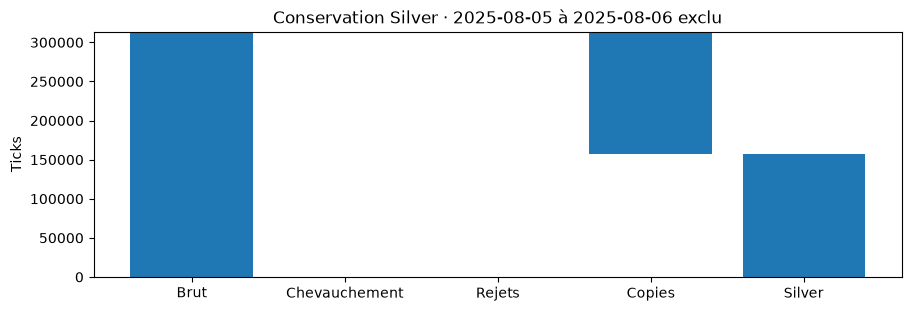

Les trois retraits sont disjoints. Les conflits conservés sont étiquetés.


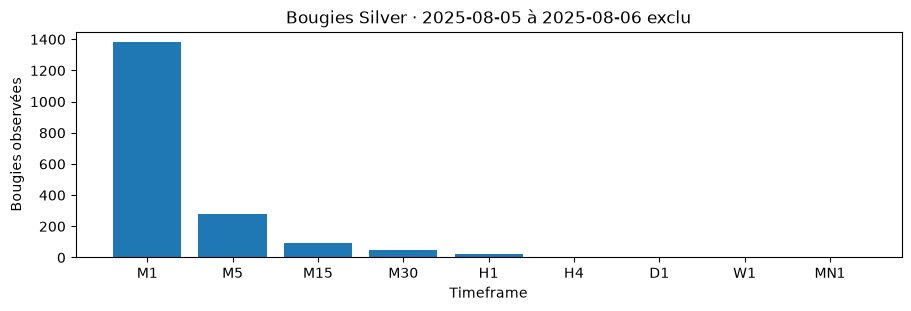

Une période sans tick ne produit aucune bougie. Le calendrier historique reste incomplet.


Métriques Spark UI {'stages': 230, 'numTasks': 897, 'numFailedTasks': 0, 'executorCpuTime': 78160083100, 'jvmGcTime': 2188, 'shuffleReadBytes': 54390851, 'shuffleWriteBytes': 54390851, 'diskBytesSpilled': 0, 'memoryBytesSpilled': 0}
normalized {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 11.535, 'chunks': ['2025-08-05']}
silver {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 11.612, 'raw': 313684, 'accepted': 313684, 'historical_overlap': 0, 'rejected': 0, 'silver': 156842, 'reconstructed': 0, 'duplicate_copies': 156842, 'conflicts': 0}
validation {'run_key': 'ee7d454dc8a8024283ce25788d6c720a150a9dff959e8e744b38fa8cedae016a', 'status': 'complete', 'elapsed_run_seconds': 113.722, 'ticks': 156842, 'volume_missing': 0, 'additional_without_historical_match': 156842, 'invalid': 0, 'first_utc': '2025-08-05 00:00:00.113000', 'last_utc': '

In [9]:
def with_higher(main,higher,tf,features,until):
    suffix='_'+tf
    good=higher.where(~F.col('is_partial'))
    w=Window.partitionBy('symbol').orderBy('available_at')
    close=F.col('available_at')
    if tf in FREQ:
        expiry=close+F.expr(f'INTERVAL {FREQ[tf]} SECONDS')
    elif tf=='W1':
        expiry=close+F.expr('INTERVAL 7 DAYS')
    else:
        expiry=F.add_months(close,1).cast('timestamp')
    limit=F.lit(until).cast('timestamp')+F.expr('INTERVAL 1 MICROSECOND')
    base=good.withColumn('next_time',F.least(F.coalesce(F.lead('available_at').over(w),limit),expiry))
    base=base.where('next_time > available_at').withColumn('join_date',F.explode(F.sequence(
        F.to_date('available_at'),F.to_date(F.col('next_time')-F.expr('INTERVAL 1 MICROSECOND')))))
    keep=[name for name in features if name in higher.columns]
    base=base.select('symbol','join_date',F.col('available_at').alias('lower'),F.col('next_time').alias('upper'),
        F.col('quality_flag').alias('quality'+suffix),*[F.col(x).alias(x+suffix) for x in keep])
    assigned=main.withColumn('join_date',F.to_date('available_at')).alias('m')
    other=base.alias('h')
    match=((F.col('m.symbol')==F.col('h.symbol')) & (F.col('m.join_date')==F.col('h.join_date')) &
           (F.col('m.available_at')>=F.col('h.lower')) & (F.col('m.available_at')<F.col('h.upper')))
    return (assigned.join(other,match,'left').select('m.*',
            F.col('h.lower').alias('available_at'+suffix), F.col('h.quality'+suffix),
            *[F.when(F.col('h.quality'+suffix).isin(*CFG['allowed_quality']),F.col('h.'+x+suffix)).alias(x+suffix) for x in keep])
            .drop('join_date'))

say('Une feature de fréquence supérieure conserve son horodatage de disponibilité et son statut de qualité.')

from tempfile import TemporaryDirectory

def test_spark():
    stamp='2025-08-05T01:00:00.000Z'
    def r(src,index,when,ask,bid,va='.002',vb='.003'):
        return (src,src+'.csv',index,None,when,ask,bid,va,vb)
    values=[r('touhid',0,stamp,'10','9'),r('touhid',1,stamp,'10','9'),
        r('jforex',0,stamp,'10','9'),r('jforex',1,stamp,'11','9'),
        r('jforex',2,'2025-08-05T01:03:00.000Z','12','11',None,None),
        r('jforex',3,'2025-08-05T01:05:00.000Z','13','12')]
    for i,clock in enumerate(['2025.01.05 03:00:00.000','2025.08.05 03:00:00.000',
                              '2025.03.30 03:30:00.000','2025.10.26 03:30:00.000']):
        line=f'{clock},14,5,14,3,0,01,0,02'
        values.append(('historical_recent','legacy_fixture.csv',i,line,None,None,None,None,None))
    decimal_line='2025.08.05 04:00:00.000,14,14,3,0,01,0,02'
    values.append(('historical_recent','legacy_fixture.csv',4,decimal_line,None,None,None,None,None))
    proof=[(sha256(decimal_line.encode()).hexdigest(),'2025-08-05T01:00:00Z',['14','14.3','.01','.02'])]
    raw=spark.createDataFrame(values,RAW_SCHEMA)
    check=normalize(clean(raw,proof),date(2025,1,1),date(2026,1,1)).persist()
    hist=check.where(F.col('source_id')=='historical_recent').orderBy('source_offset').take(5)
    assert [row.timestamp_utc.hour for row in hist[:2]]==[1,0]
    assert all(row.reason=='ambiguous_or_nonexistent_local_clock' for row in hist[2:4])
    assert hist[4].reason=='negative_spread' and hist[4].is_reconstructed
    strict=check.where("reason IS NULL AND source_id IN ('touhid','jforex')")
    merged=reconcile(strict).persist()
    assert merged.count()==5
    assert merged.where("timestamp_utc = TIMESTAMP '2025-08-05 01:00:00' AND ask=10").count()==2
    assert merged.where('NOT has_volume').count()==1
    assert merged.where("quality_flag='CONFLICT'").count()==3
    m5=bar_frame(merged,'M5',date(2025,8,5),date(2025,8,6))
    m15=bar_frame(merged,'M15',date(2025,8,5),date(2025,8,6))
    first=m5.orderBy('bar_open_time').first()
    assert (int(first.ask_open),int(first.ask_close),int(first.ask_high),first.tick_count)==(10,12,12,4)
    assert m15.first().tick_count==5
    join=with_higher(m5.withColumn('selected',F.lit(1.0)),m15.withColumn('selected',F.lit(8.0)),
                     'M15',['selected'],'2025-08-06')
    assert not join.where('available_at_M15>available_at').take(1)
    assert all(row.selected_M15 is None for row in join.take(2))
    # Même entrée avec une autre distribution physique.
    rerun=reconcile(strict.repartition(3))
    assert not merged.exceptAll(rerun).take(1)
    assert not rerun.exceptAll(merged).take(1)
    merged.unpersist()
    check.unpersist()
    with TemporaryDirectory(prefix='spark_idempotence_',dir=CFG['scratch']) as folder:
        p=Path(folder)/'checkpoint'
        publish(spark.range(3),p)
        publish(spark.range(3),p)
        assert spark.read.parquet(str(p)).count()==3
    return True
if active('17'):
    assert test_spark()
    finish('tests_silver',passed=['decimals','UTC','DST','multiplicity','multisource','distinct_quotes',
                                  'OHLC','timeframes','idempotence','reproducibility'])
else:
    status('tests_silver')



if completed('silver'):
    import matplotlib.pyplot as plt
    m=manifest('silver')
    parent=m['raw']
    labels=['Brut','Chevauchement','Rejets','Copies','Silver']
    mov=[parent,-m['historical_overlap'],-m['rejected'],-m['duplicate_copies'],m['silver']]
    bottoms=[0,parent+mov[1],parent+mov[1]+mov[2],m['silver'],0]
    fig,ax=plt.subplots(figsize=(9,3),layout='constrained')
    ax.bar(labels,[abs(x) for x in mov],bottom=bottoms)
    ax.set(title=f'Conservation Silver · {start} à {end} exclu',ylabel='Ticks')
    display(fig)
    plt.close(fig)
    print('Les trois retraits sont disjoints. Les conflits conservés sont étiquetés.')
if completed('bars'):
    import matplotlib.pyplot as plt
    counts=manifest('bars')['counts']
    fig,ax=plt.subplots(figsize=(9,3),layout='constrained')
    ax.bar(counts.keys(),counts.values())
    ax.set(title=f'Bougies Silver · {start} à {end} exclu',xlabel='Timeframe',ylabel='Bougies observées')
    display(fig)
    plt.close(fig)
    print('Une période sans tick ne produit aucune bougie. Le calendrier historique reste incomplet.')
stage_report()